# Linear Regression - 线性回归问题

## Problem Analysis - 问题分析 

线性回归基于几个简单的假设： 首先，假设自变量X和因变量y之间的关系是线性的 <br>
即y可以表示为x中元素的加权和，这里通常允许包含观测值的一些噪声； <br>

其次，我们假设任何噪声都比较正常，如噪声遵循正态分布。


### 线性模型

1. 设计模型
    - 给定 $n$ 维输入：$\mathbf{x} = [x_1, x_2, \cdots, x_n]^T$

    - 线性模型有一个 $n$ 维权重和一个标量偏差：**加权计算和偏置计算**

    $$
    \mathbf{w} = [w_1, w_2, \cdots, w_n]^T, \quad b
    $$

    - 输出是输入的加权和：

    $$
    y = w_1x_1 + w_2x_2 + \cdots + w_nx_n + b
    $$

    - 向量版本：$y = \langle \mathbf{w}, \mathbf{x} \rangle + b$

        线性模型可以看做单层的神经网络 <br>
        给定一个数据集，我们的目标是寻找模型的权重和偏置， 使得根据模型做出的预测大体符合数据里的真实价格。 <br>
        输出的预测值由输入特征通过线性模型的仿射变换决定，仿射变换由所选权重和偏置确定。


2. 数据分析、预处理、特征工厂 - 这里先省略，需要结合具体例子分析


3. 模型训练
    分解数据集 为训练集、测试集（可省略）、验证集<br>
    通过训练数据来调整参数
    调整参数的依据 - **损失函数**

    - 对于线性回归，最常用的是 **均方误差**:
        
        $ l^{(i)}(\mathbf{w}, b) = \frac{1}{2} \left( \hat{y}^{(i)} - y^{(i)} \right)^2. $

        $ L(\mathbf{w}, b) 
    = \frac{1}{n} \sum_{i=1}^{n} \ell^{(i)}(\mathbf{w}, b)
    = \frac{1}{n} \sum_{i=1}^{n} \frac{1}{2} \left( \mathbf{w}^\top \mathbf{x}^{(i)} + b - y^{(i)} \right)^2 $

        $ \ell(\mathbf{X}, \mathbf{y}, \mathbf{w}, b) 
        = \frac{1}{2n} \sum_{i=1}^{n} \left( y_i - \langle \mathbf{x}_i, \mathbf{w} \rangle - b \right)^2
        = \frac{1}{2n} \left\| \mathbf{y} - \mathbf{X}\mathbf{w} - b \right\|^2. $

    - **样本总损失**

        $ \mathbf{w}^*,b^*=\underset{\mathbf{w},b}{\operatorname*{\operatorname*{argmin}}} \; L(\mathbf{w},b) $  找到w，b向量，使得w，b最小
        

    - 优化方法 - 自动调整参数


    - 超参数调优 - 手动调整

4. 模型优化
    评估模型泛化能力
    判断是否过拟合/欠拟合
    交叉验证
    残差分析

## 手写实现线性回归模型

torch.rand(2, 3): tensor([[0.4963, 0.7682, 0.0885],
        [0.1320, 0.3074, 0.6341]])
torch.arange(10): tensor([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
tensor([[ 1.2645, -0.6874,  0.1604],
        [-0.6065, -0.7831,  1.0622]])
features: tensor([[ 0.5667,  0.7935],
        [ 0.5988, -1.5551],
        [-0.3414,  1.8530],
        [ 0.4681, -0.1577],
        [-0.1734,  0.1835]]) 
label: tensor([[ 2.6401],
        [10.6838],
        [-2.7855],
        [ 5.6756],
        [ 3.2210]])


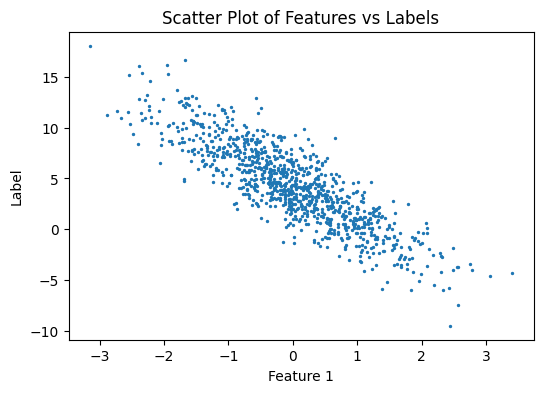

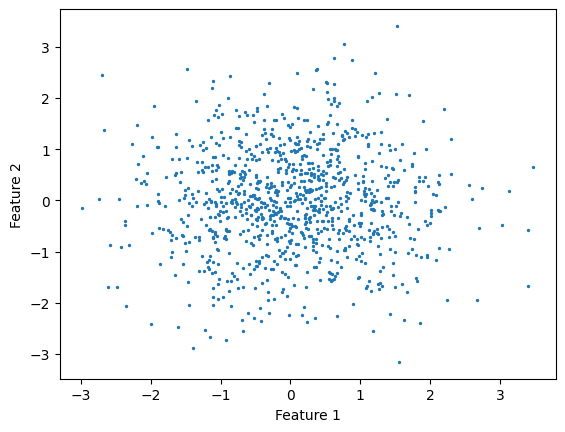

In [6]:
import random
import torch
from d2l import torch as d2l
import matplotlib.pyplot as plts

# 随机创建一个二维张量
torch.manual_seed(0) # 设置随机种子，确保每次运行结果相同
print('torch.rand(2, 3):', torch.rand(2, 3))
# 生成一个包含0到9的整数序列的张量
print('torch.arange(10):', torch.arange(10))

# torch.set_printoptions(threshold=float('inf')) # 设置打印选项，threshold=float('inf')表示打印所有元素，不使用省略号
print(torch.normal(0, 1, (2, 3))) # 生成一个包含2行3列的张量，元素服从均值为0，标准差为1的正态分布


# 构造人造数据集
def synthetic_data(w, b, num_examples):  #@save
    """生成y=Xw+b+噪声"""
    X = torch.normal(0, 1, (num_examples, len(w))) # 生成均值为0，标准差为1的随机数，形状为(num_examples, len(w))
    # print('X:', X)
    y = torch.matmul(X, w) + b # 矩阵乘法，得到线性关系的结果
    # print('y:', y)
    # print('y shape:', y.shape) # 得到的是一个向量（1维张量）
    y += torch.normal(0, 0.01, y.shape) # 添加噪声，生成的噪声服从均值为0，标准差为0.01）的正态分布，形状与y相同
    # print('y with noise:', y)

    return X, y.reshape((-1, 1)) # 返回特征X和标签y，标签y被重塑为列向量
    # reshape((-1, 1))的作用是将y重塑为一个列向量，其中-1表示自动计算行数，1表示列数为1

true_w = torch.tensor([2.0, -3.4]) # 定义实际权重参数
# 必须至少有一个为float，PyTorch 要求参与运算的两个张量（Tensor）必须是同一种数据类型。
# 列表中有一个浮点数（-3.4），PyTorch 在处理 torch.matmul(X, w) 时，会自动把这个列表转换成 Float (float32) 类型的张量
true_b = 4.2 # 定义实际偏置参数
features, labels = synthetic_data(true_w, true_b, 1000) # 生成1000个样本的特征和标签

print('features:', features[:5],'\nlabel:', labels[:5]) # 打印前5个样本的特征和标签
# features代表特征，即输入数据，labels代表标签，即人造的线性关系的输出结果加上噪声。


# pltd2l = d2l.plt
# pltd2l.scatter(features[:, (1)].detach().numpy(), labels.detach().numpy(), 1);

plts.figure(figsize=(6, 4)) # 设置图像大小为6x4英寸
plts.title('Scatter Plot of Features vs Labels') # 设置图表标题
plts.xlabel('Feature 1') # 设置x轴标签
plts.ylabel('Label') # 设置y轴标签
# print('features[:, 1]:', features[:, 1]) # 打印特征的第二列（索引为1）
plts.scatter(features[:, 1].detach().numpy(), labels.detach().numpy(), s=2); 
plts.show()
plts.xlabel('Feature 1') # 设置x轴标签
plts.ylabel('Feature 2') # 设置y轴标签
plts.scatter(features[:, 0].detach().numpy(), features[:, 1].detach().numpy(), s=2);
# detach()方法用于从计算图中分离张量，使其不再参与梯度计算，numpy()方法将张量转换为NumPy数组，
# scatter()函数用于绘制散点图，第一个参数是x轴数据，第二个参数是y轴数据，第三个参数是点的大小，这里设置为2。
# 绘制散点图，x轴为特征的第二列（索引为1），y轴为标签，点的大小为1

In [ ]:
def data_iter(batch_size, features, labels): # 定义一个函数，用于生成小批量数据
    num_examples = len(features) # 获取样本数量
    indices = list(range(num_examples)) # 创建一个包含样本索引的列表
    # 这些样本是随机读取的，没有特定的顺序
    random.shuffle(indices) # 打乱索引列表，确保每次迭代时样本的顺序不同
    print('indices:', indices)
    for i in range(0, num_examples, batch_size): # 从0开始，以batch_size为步长，遍历样本索引
        print('i:', i)
        print('indices[i: min(i + batch_size, num_examples)]:', indices[i: min(i + batch_size, num_examples)])
        batch_indices = torch.tensor(indices[i: min(i + batch_size, num_examples)])
        # 通过索引获取对应的特征和标签，并使用yield关键字返回一个生成器对象，每次调用生成器时都会返回一个小批量的数据。
        yield features[batch_indices], labels[batch_indices]
        # yield关键字使函数成为一个生成器，可以在需要时动态生成数据，而不是一次性生成所有数据，节省内存。
        # yield 是 Python 中用于定义生成器函数的关键字，它让函数可以"暂停"执行并"记住"状态，下次从暂停处继续。

batch_size = 10

for X, y in data_iter(batch_size, features, labels):
    print(X , '===', '\n', y)
    break

indices: [259, 300, 996, 486, 108, 651, 244, 82, 56, 933, 362, 978, 856, 383, 775, 467, 115, 164, 110, 562, 886, 643, 599, 865, 246, 479, 347, 348, 492, 909, 502, 917, 157, 290, 373, 624, 213, 938, 851, 11, 272, 78, 297, 713, 973, 44, 679, 657, 808, 930, 279, 971, 683, 832, 607, 524, 513, 595, 576, 728, 809, 54, 940, 874, 143, 676, 681, 446, 569, 758, 976, 703, 872, 510, 547, 266, 353, 639, 986, 53, 240, 983, 817, 58, 341, 741, 73, 968, 582, 357, 665, 190, 222, 235, 815, 471, 631, 447, 632, 993, 645, 218, 326, 667, 426, 671, 542, 250, 324, 188, 964, 534, 789, 577, 415, 680, 705, 417, 984, 150, 729, 61, 94, 601, 375, 980, 857, 951, 468, 437, 838, 167, 474, 883, 452, 113, 35, 538, 257, 572, 824, 51, 604, 13, 818, 248, 124, 183, 195, 619, 586, 432, 253, 848, 539, 737, 372, 744, 499, 846, 716, 554, 761, 330, 876, 122, 200, 88, 332, 514, 731, 448, 407, 116, 409, 804, 263, 114, 957, 730, 908, 630, 710, 813, 197, 786, 943, 570, 686, 805, 501, 443, 858, 475, 495, 868, 0, 746, 286, 854, 368, 19

In [ ]:
w = torch.normal(0, 0.01, size=(2,1), requires_grad=True) 
# 生成一个包含2行1列的张量(权重参数)，元素服从均值为0，标准差为0.01的正态分布，
# 并且设置requires_grad=True（反向传播求梯度），使其成为可训练的参数
print('w:', w[:5])
b = torch.zeros(1, requires_grad=True) 
# 生成一个包含1个元素的张量(偏置参数)，元素为0，并且设置requires_grad=True，使其成为可训练的参数
print('b:', b)

# 定义模型, 得到预测值
def linreg(X, w, b):  #@save
    """线性回归模型"""
    return torch.matmul(X, w) + b

# 定义损失函数
def squared_loss(y_hat, y):  #@save
    """均方损失"""
    return (y_hat - y.reshape(y_hat.shape)) ** 2 / 2

# 定义优化算法
# 对于每个参数，更新其值，更新的方式是：
# param -= lr * param.grad / batch_size，其中lr是学习率，param.grad是参数的梯度，batch_size是小批量的大小。
def sgd(params, lr, batch_size):  #@save
    """小批量随机梯度下降"""
    with torch.no_grad():
        for param in params:
            param -= lr * param.grad / batch_size
            print('param:', param)
            print('param.grad:', param.grad)
            param.grad.zero_() # 将参数的梯度清零，以便下一次迭代时重新计算梯度

# 在优化算法中，使用torch.no_grad()上下文管理器来禁用梯度计算
# 节省内存（不保存中间结果用于反向传播）
# 加速计算（跳过自动求导机制）
# 避免不必要的梯度累积




# 训练模型
lr = 0.02 # 学习率超参
num_epochs = 3 # 迭代次数
net = linreg # 模型函数
loss = squared_loss

for epoch in range(num_epochs):
    for X, y in data_iter(batch_size, features, labels):
        l = loss(net(X, w, b), y)  # X和y的小批量损失
        # 因为l形状是(batch_size,1)，而不是一个标量。l中的所有元素被加到一起，
        # 并以此计算关于[w,b]的梯度
        l.sum().backward()
        sgd([w, b], lr, batch_size)  # 使用参数的梯度更新参数
    with torch.no_grad(): # 在评估模型时，我们不需要计算梯度，因此使用torch.no_grad()上下文管理器来禁用梯度计算，以节省内存和计算资源。
        train_l = loss(net(features, w, b), labels) # 计算所有样本的损失
        print(f'epoch {epoch + 1}, loss {float(train_l.mean()):f}')


print(f'w的估计误差: {true_w - w.reshape(true_w.shape)}')
print(f'b的估计误差: {true_b - b}')

w: tensor([[-0.0095],
        [-0.0136]], grad_fn=<SliceBackward0>)
b: tensor([0.], requires_grad=True)
i: 0
indices[i: min(i + batch_size, num_examples)]: [137, 80, 42, 294, 175, 639, 562, 951, 893, 708]
param: tensor([[ 0.0971],
        [-0.0942]], requires_grad=True)
param.grad: tensor([[-53.3052],
        [ 40.2907]])
param: tensor([0.0621], requires_grad=True)
param.grad: tensor([-31.0542])
i: 10
indices[i: min(i + batch_size, num_examples)]: [628, 212, 712, 306, 794, 182, 59, 704, 710, 573]
param: tensor([[ 0.1638],
        [-0.1516]], requires_grad=True)
param.grad: tensor([[-33.3852],
        [ 28.6823]])
param: tensor([0.1449], requires_grad=True)
param.grad: tensor([-41.3959])
i: 20
indices[i: min(i + batch_size, num_examples)]: [991, 617, 603, 230, 280, 729, 3, 484, 955, 786]
param: tensor([[ 0.2194],
        [-0.3027]], requires_grad=True)
param.grad: tensor([[-27.7664],
        [ 75.5719]])
param: tensor([0.2680], requires_grad=True)
param.grad: tensor([-61.5397])
i: 30
in

X_all shape: torch.Size([1000, 2])
y_all shape: torch.Size([1000, 1])
X_all: tensor([[ 0.5667,  0.7935],
        [ 0.5988, -1.5551],
        [-0.3414,  1.8530],
        [ 0.4681, -0.1577],
        [-0.1734,  0.1835]])
y_all: tensor([[ 2.6401],
        [10.6838],
        [-2.7855],
        [ 5.6756],
        [ 3.2210]])
w_vis: tensor([[-0.0578],
        [ 0.0660]], requires_grad=True)
b_vis: tensor([0.], requires_grad=True)
   epoch  step        w1        w2         b       loss  grad_norm
0      0     0 -0.057759  0.065980  0.000000  17.662519        NaN
1      1     1 -0.050526 -0.070539  0.142956  16.560843   6.593462
2      1     2 -0.006179 -0.179874  0.267717  15.577251   5.723835
3      1     3  0.045750 -0.293738  0.378625  14.647214   5.573968
4      1     4  0.114020 -0.418246  0.525613  13.541341   6.812437


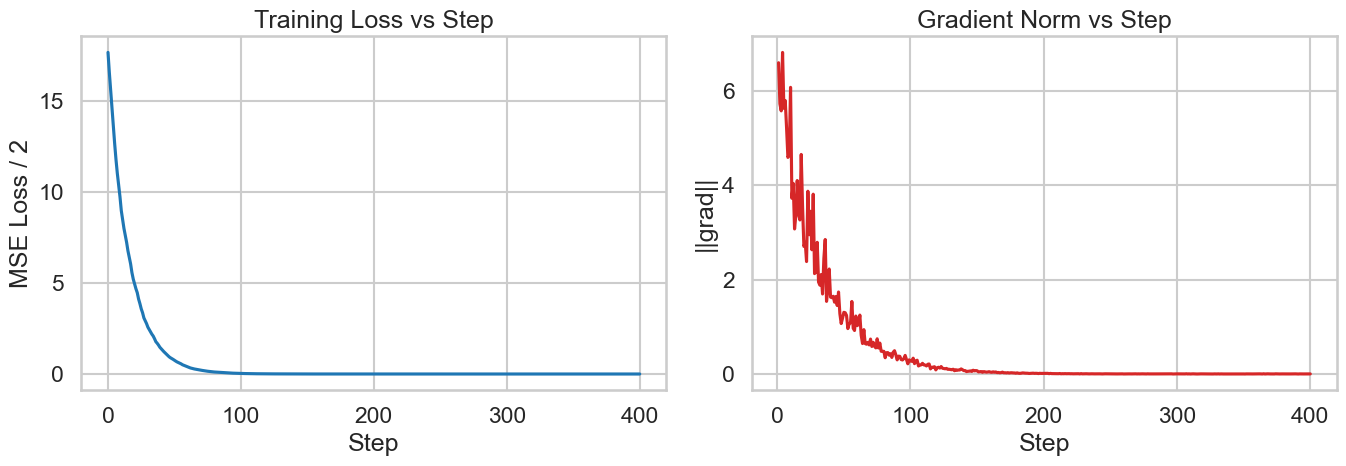

x_np: [[ 0.5666506   0.79350835]
 [ 0.59883946 -1.5550951 ]
 [-0.3413604   1.8530061 ]
 ...
 [ 1.4137628  -0.7073212 ]
 [-0.8812907  -0.58953506]
 [ 0.23909646 -2.3830633 ]]
w1_grid: [-5.57759166e-01 -5.26867303e-01 -4.95975440e-01 -4.65083577e-01
 -4.34191715e-01 -4.03299852e-01 -3.72407989e-01 -3.41516126e-01
 -3.10624264e-01 -2.79732401e-01 -2.48840538e-01 -2.17948675e-01
 -1.87056812e-01 -1.56164950e-01 -1.25273087e-01 -9.43812240e-02
 -6.34893612e-02 -3.25974985e-02 -1.70563568e-03  2.91862271e-02
  6.00780899e-02  9.09699527e-02  1.21861815e-01  1.52753678e-01
  1.83645541e-01  2.14537404e-01  2.45429267e-01  2.76321129e-01
  3.07212992e-01  3.38104855e-01  3.68996718e-01  3.99888580e-01
  4.30780443e-01  4.61672306e-01  4.92564169e-01  5.23456032e-01
  5.54347894e-01  5.85239757e-01  6.16131620e-01  6.47023483e-01
  6.77915346e-01  7.08807208e-01  7.39699071e-01  7.70590934e-01
  8.01482797e-01  8.32374659e-01  8.63266522e-01  8.94158385e-01
  9.25050248e-01  9.55942111e-01  9.8

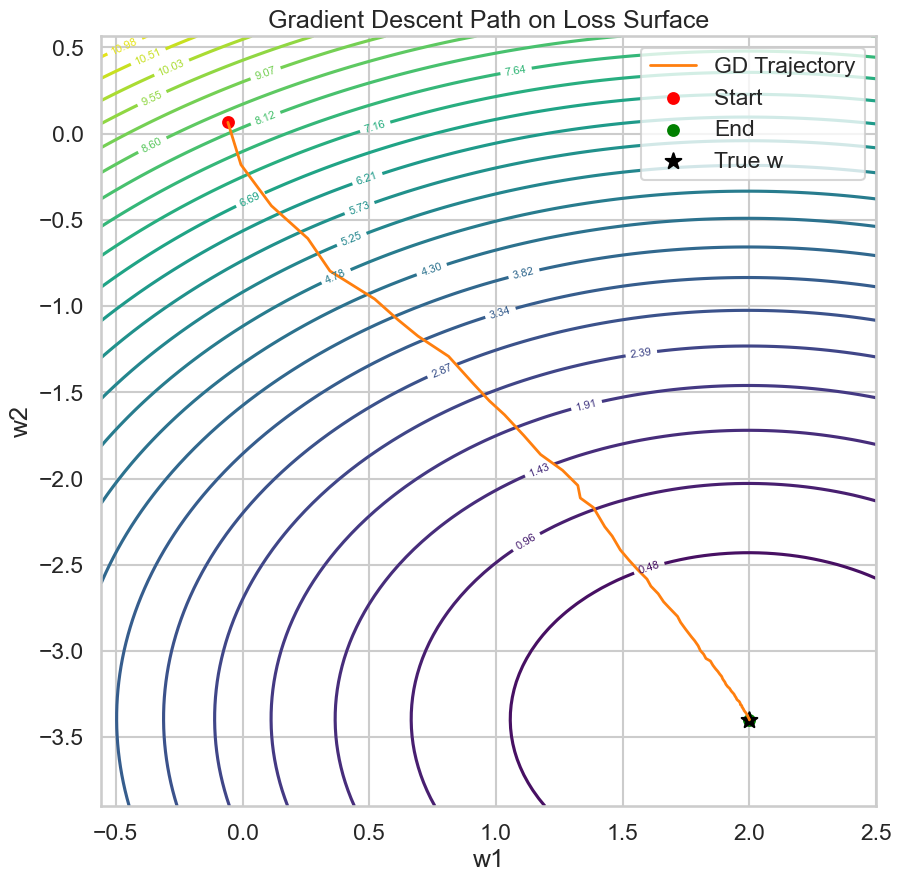

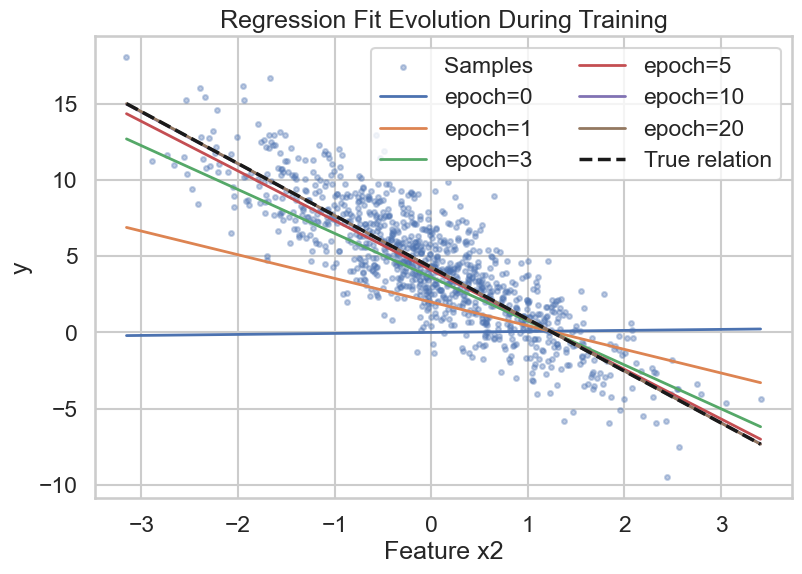

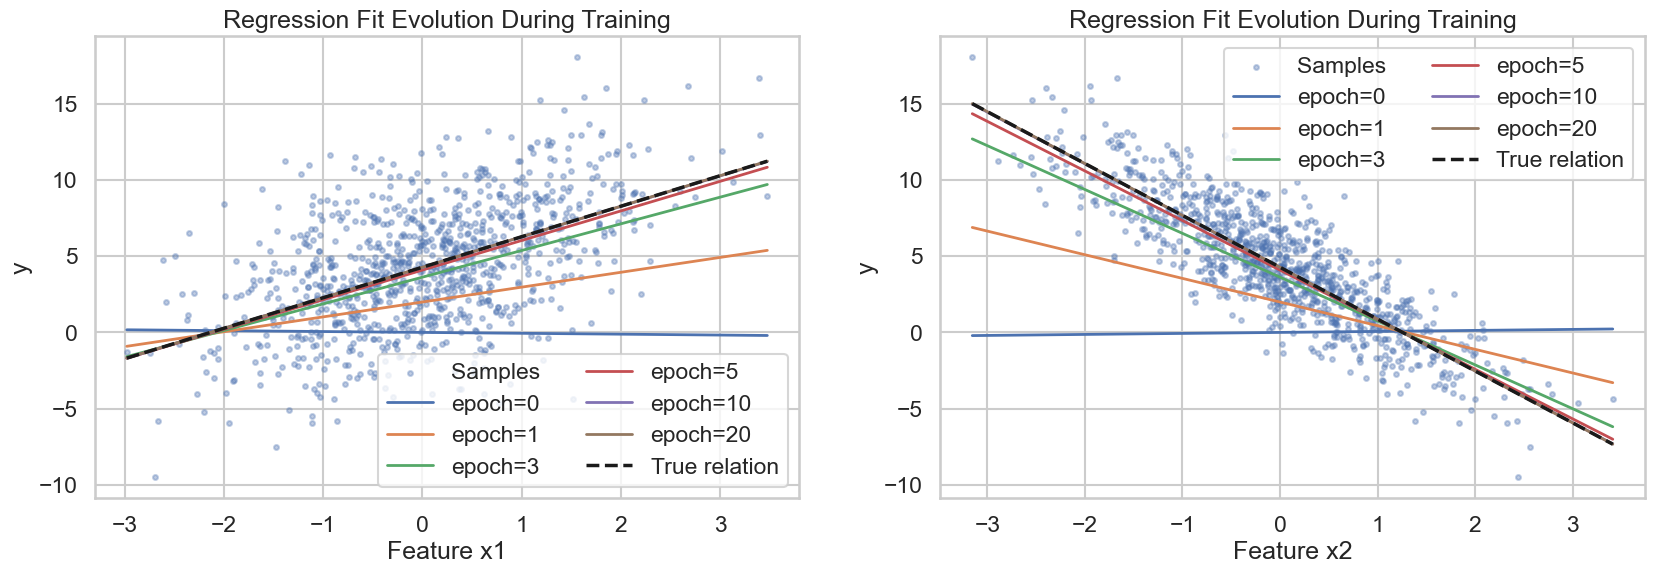

<Figure size 900x600 with 0 Axes>

<Figure size 900x600 with 0 Axes>

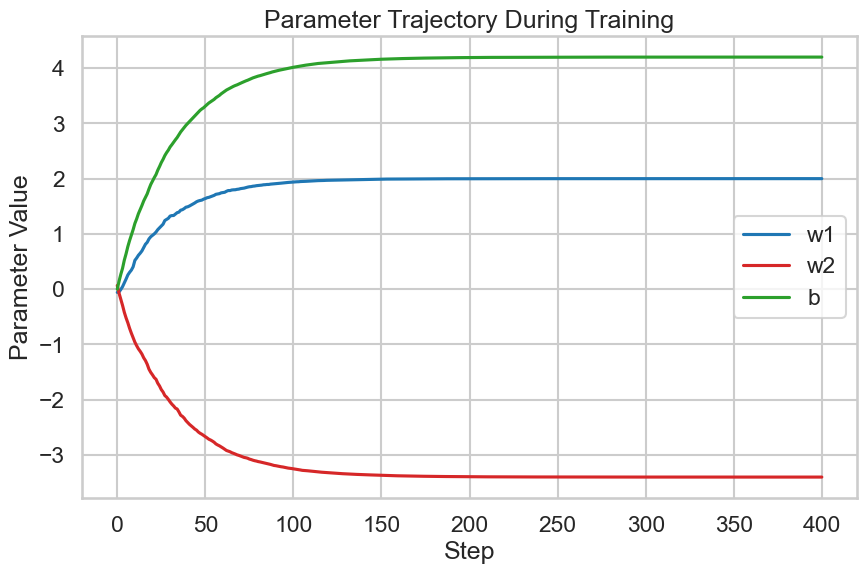

可视化完成：已生成 loss/grad 曲线、参数下降轨迹、拟合曲线演化图。


In [ ]:
# 训练过程可视化：损失曲线、梯度下降轨迹、回归拟合过程
import numpy as np
import pandas as pd
import seaborn as sns # Seaborn是一个基于Matplotlib的统计数据可视化库，提供了更高级的接口和更美观的默认样式
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")

# 如果前面的单元已经运行，这些变量会直接可用
assert "features" in globals() and "labels" in globals(), "请先运行上方数据构建单元" # 检查是否已经定义了features和labels变量，如果没有定义则抛出异常并提示用户先运行数据构建单元
assert "linreg" in globals() and "squared_loss" in globals(), "请先运行上方模型定义单元" # 检查是否已经定义了linreg和squared_loss函数，如果没有定义则抛出异常并提示用户先运行模型定义单元

X_all = features.detach().float()
y_all = labels.detach().float()

print('X_all shape:', X_all.shape) # 打印X_all的形状
print('y_all shape:', y_all.shape) # 打印y_all的形状
print('X_all:', X_all[:5]) # 打印X_all的前5行
print('y_all:', y_all[:5]) # 打印y_all的前5行

# 静默版小批量迭代器（不打印每一步）
def data_iter_silent(batch_size, features, labels):
    num_examples = len(features) # 获取样本数量
    indices = list(range(num_examples)) # 创建一个包含样本索引的列表
    random.shuffle(indices) # 打乱索引列表，确保每次迭代时样本的顺序不同
    for i in range(0, num_examples, batch_size): # 从0开始，以batch_size为步长，遍历样本索引
        batch_indices = torch.tensor(indices[i:min(i + batch_size, num_examples)]) # 获取当前小批量的索引
        yield features[batch_indices], labels[batch_indices] # 通过索引获取对应的特征和标签，并使用yield关键字返回一个生成器对象，每次调用生成器时都会返回一个小批量的数据。

# 为了演示训练轨迹，重新初始化一组参数
w_vis = torch.normal(0, 0.1, size=(2, 1), requires_grad=True)
print('w_vis:', w_vis)
b_vis = torch.zeros(1, requires_grad=True)
print('b_vis:', b_vis)
lr_vis = 0.03
num_epochs_vis = 20
batch_size_vis = 50

history = [] # 用于记录训练过程中的参数和损失等信息
checkpoints = [] # 用于记录每个 epoch 的参数快照
step = 0 # 记录训练步骤数，用于绘制损失曲线和梯度范数曲线的横轴

# 保存初始状态
with torch.no_grad():
    init_loss = float(squared_loss(linreg(X_all, w_vis, b_vis), y_all).mean())
    history.append({
        "epoch": 0,
        "step": step,
        "w1": float(w_vis[0, 0]),
        "w2": float(w_vis[1, 0]),
        "b": float(b_vis[0]),
        "loss": init_loss,
        "grad_norm": np.nan,
    })
    checkpoints.append((0, float(w_vis[0, 0]), float(w_vis[1, 0]), float(b_vis[0])))

# 训练模型并记录训练过程中的参数和损失等信息
for epoch in range(1, num_epochs_vis + 1):
    for X_batch, y_batch in data_iter_silent(batch_size_vis, X_all, y_all):
        pred = linreg(X_batch, w_vis, b_vis) # 计算当前小批量的预测值
        batch_loss = squared_loss(pred, y_batch).mean() # 计算当前小批量的损失（平均损失）
        batch_loss.backward() # 反向传播计算梯度（对参数的梯度）

        # print('w_vis.grad:', w_vis.grad) # 打印权重参数的梯度
        # print('b_vis.grad:', b_vis.grad) # 打印偏置参数的梯度
        grad_norm = float(torch.sqrt((w_vis.grad ** 2).sum() + (b_vis.grad ** 2).sum())) # 计算当前小批量的梯度范数，用于监控训练过程中的梯度大小
        # print('grad_norm:', grad_norm) # 打印梯度范数
        # 这里计算梯度范数，是为了把“多个参数的梯度”压缩成一个可监控的标量，便于观察训练动态。

        with torch.no_grad(): # torch.no_grad()上下文管理器来禁用梯度计算，节省内存和计算资源
            w_vis -= lr_vis * w_vis.grad
            b_vis -= lr_vis * b_vis.grad
            w_vis.grad.zero_()
            b_vis.grad.zero_()

            full_loss = float(squared_loss(linreg(X_all, w_vis, b_vis), y_all).mean())

        step += 1
        history.append({
            "epoch": epoch,
            "step": step,
            "w1": float(w_vis[0, 0]),
            "w2": float(w_vis[1, 0]),
            "b": float(b_vis[0]),
            "loss": full_loss,
            "grad_norm": grad_norm,
        })

    # 每个 epoch 记录一次拟合快照
    with torch.no_grad():
        checkpoints.append((epoch, float(w_vis[0, 0]), float(w_vis[1, 0]), float(b_vis[0])))

hist_df = pd.DataFrame(history) # 将训练历史记录转换为 Pandas DataFrame，便于后续分析和可视化
print(hist_df.head()) # 打印训练历史记录的前5行，查看记录的内容和格式

# 1) loss 与梯度范数
fig, axes = plt.subplots(1, 2, figsize=(14, 5)) # 创建一个包含1行2列子图的图形对象，fig是整个图形对象，axes是一个包含两个子图对象的数组
sns.lineplot(data=hist_df, x="step", y="loss", ax=axes[0], color="#1f77b4") # lineplot函数用于绘制折线图，sns是一个基于Matplotlib的统计数据可视化库，提供了更高级的接口和更美观的默认样式
# data参数指定数据源，x参数指定横轴数据，y参数指定纵轴数据，ax参数指定绘图的子图对象，color参数指定线条颜色
axes[0].set_title("Training Loss vs Step")
axes[0].set_xlabel("Step")
axes[0].set_ylabel("MSE Loss / 2")

sns.lineplot(data=hist_df.dropna(), x="step", y="grad_norm", ax=axes[1], color="#d62728")
axes[1].set_title("Gradient Norm vs Step")
axes[1].set_xlabel("Step")
axes[1].set_ylabel("||grad||")
plt.tight_layout() # 调整子图之间的间距，使得整体布局更紧凑，避免子图之间的标签和标题重叠
plt.show()

# 2) 参数空间中的梯度下降轨迹（w1, w2）
x_np = X_all.numpy() # 将特征张量转换为 NumPy 数组，便于后续计算和可视化
print('x_np:', x_np) # 打印x_np的形状，查看转换后的特征数组的维度
y_np = y_all.squeeze().numpy() # 将标签张量转换为 NumPy 数组，并使用squeeze()方法去除单维度，使其成为一维数组，便于后续计算和可视化

w1_min, w1_max = hist_df["w1"].min() - 0.5, hist_df["w1"].max() + 0.5 # 计算w1的最小值和最大值，并在其基础上扩展0.8的范围，以便在绘制参数空间时有足够的边距 
w2_min, w2_max = hist_df["w2"].min() - 0.5, hist_df["w2"].max() + 0.5 # 计算w2的最小值和最大值，并在其基础上扩展0.8的范围，以便在绘制参数空间时有足够的边距
w1_grid = np.linspace(start=w1_min, stop=w1_max, num=100) # linspace函数用于生成等间距的数值序列，
# start参数指定序列的起始值，stop参数指定序列的结束值，num参数指定生成的数值个数，这里生成100个数值
w2_grid = np.linspace(start=w2_min, stop=w2_max, num=100) 
print('w1_grid:', w1_grid) # 打印w1_grid，查看生成的等间距数值序列
print('w2_grid:', w2_grid) # 打印w2_grid，查看生成的等间距数值序列

print('w1_grid shape:', w1_grid.shape) # 打印w1_grid的形状，查看生成的等间距数值序列的维度

W1, W2 = np.meshgrid(w1_grid, w2_grid) # meshgrid函数用于生成网格坐标矩阵，w1_grid和w2_grid分别是w1和w2的数值序列，
print('W1:', W1) # 打印W1，查看生成的网格坐标矩阵
print('W2:', W2) # 打印W2，查看生成的网格坐标矩阵
print('W1 shape:', W1.shape) # 打印W1的形状，查看生成的网格坐标矩阵的维度
# 生成的W1和W2分别是对应的网格坐标矩阵，便于后续计算损失函数在参数空间中的值

#  写None的位置增加一个维度，便于后续与特征矩阵进行广播计算
print('W1[None, :, :] shape:', W1[None, :, :].shape) # (100, 100) -> (1, 100, 100), 左边增加一个维度，直接在外网加上一层[]
print('W1[ :, :, None]shape:', W1[ :, :, None].shape) # (100, 100) -> (100, 100, 1), 右边增加一个维度，在最后加上一层[], 实际上是把内部元素拆分成一个个单独的元素，形成一个新的维度
print('NoneW1:', W1[ :, :, None])
print('W1[ :, :, None]:', W1[ None, :, ])


b_fixed = hist_df["b"].iloc[-1] # 使用训练过程中最后一个 epoch 的偏置参数作为固定值，计算损失函数在参数空间中的值
# iloc[-1]表示获取DataFrame中最后一行的数据，这里获取的是最后一个 epoch 的偏置参数值

print('x_np[:, 0][:, None, None] shape:', x_np[:, 0][:, None, None].shape) # (1000, 1, 1)


print('x_np[:, 0][:, None, None]:', x_np[:, 0][:, None, None]) # 打印特征的第一列（索引为0), [:, None, None]的作用是将一维数组转换为三维数组，第一维是样本数量，第二维和第三维都是1，便于后续与网格坐标矩阵进行广播计算
print('x_np[:, 1][:, None, None]:', x_np[:, 1][:, None, None]) # 打印特征的第二列（索引为1)


pred_grid = ( 
    x_np[:, 0][:, None, None] * W1[None, :, :]  # x_np[:, 0][:, None, None] 是(1000, 1, 1)，W1[None, :, :] 是(1, 100, 100)，通过广播机制进行计算，得到一个形状为(1000, 100, 100)的数组，表示在参数空间中每个点对应的预测值
    + x_np[:, 1][:, None, None] * W2[None, :, :] 
    + b_fixed
) # pred_grid的到的结果是一个三维数组，表示在参数空间中每个点对应的预测值。x_np[:, 0]和x_np[:, 1]分别是特征矩阵的第一列和第二列，W1和W2是参数空间的网格坐标矩阵，b_fixed是固定的偏置参数值。通过广播机制，将特征矩阵与网格坐标矩阵进行计算，得到每个参数组合对应的预测值。

# 这段代码本质上是在做一件事：把“模型预测”在一个二维参数网格上一次性全部算出来（向量化计算），用于可视化或分析 loss landscape。
# 第i个样本，在参数（W1[j,k]，W2[j,k]）下的预测值

print('pred_grid shape:', pred_grid.shape) # 打印pred_grid的形状，查看根据网格坐标矩阵计算得到的预测值的维度

Z = ((pred_grid - y_np[:, None, None]) ** 2).mean(axis=0) / 2 # 计算损失函数在参数空间中的值，pred_grid是根据网格坐标矩阵计算得到的预测值，y_np是实际标签值，
# Z = torch.arange(10000).reshape(100, 100) 
# 计算预测值与实际标签值之间的均方误差，并除以2，得到损失函数在参数空间中的值Z，便于后续绘制等高线图
print('Z: ', Z)

plt.figure(figsize=(10, 10))
my_levels = np.linspace(Z.min(), Z.max(), 25)
contour = plt.contour(W1, W2, Z, levels=my_levels, cmap="viridis") # contour函数用于绘制等高线图，W1和W2是参数空间的网格坐标矩阵，Z是损失函数在参数空间中的值，levels参数指定等高线的数量，cmap参数指定颜色映射，这里使用"viridis"颜色映射
# plt.scatter(W1, W2) # scatter函数用于绘制散点图，W1和W2是参数空间的网格坐标矩阵，c参数指定散点的颜色，这里使用Z作为颜色值，cmap参数指定颜色映射，这里使用"viridis"颜色映射，s参数指定散点的大小，edgecolors参数指定散点边缘的颜色，这里设置为黑色
# plt.plot(W1, W2) # plot函数用于绘制线条，W1和W2是参数空间的网格坐标矩阵，color参数指定线条颜色，这里设置为黑色，linewidth参数指定线条宽度，这里设置为0.5
# print(len(W1.shape))
# print(len(W1))
# print(type(W1.shape[1]))
# n, m = W1.shape
# print('n:', n)
# print('m:', m)
# for j in range(W1.shape[1]):
#     plt.plot(W1[:, j], W2[:, j])
# for j in range(len(W1)):
#     plt.plot(W1[j, :], W2[j, :])



plt.clabel(contour, inline=True, fontsize=8) # clabel函数用于在等高线图上添加标签，
# contour参数指定等高线对象，inline参数指定标签是否内嵌在等高线上，fontsize参数指定标签的字体大小
# contour(X, Y, Z) 其实是在表达一个函数：Z = f (X , Y)，contour函数会根据Z的值在X-Y平面上绘制等高线



traj = hist_df.iloc[::max(1, len(hist_df) // 200)] # 从训练历史记录中抽取部分数据点，用于绘制梯度下降轨迹，
# ::max(1, len(hist_df) // 200)表示每隔一定步数抽取一个数据点，确保轨迹图不会过于密集
plt.plot(traj["w1"], traj["w2"], color="#ff7f0e", linewidth=2, label="GD Trajectory") # plot函数用于绘制线条，traj["w1"]和traj["w2"]分别是抽取的数据点的w1和w2参数值，color参数指定线条颜色，linewidth参数指定线条宽度，label参数指定图例标签
plt.scatter(traj["w1"].iloc[0], traj["w2"].iloc[0], color="red", s=60, label="Start")
plt.scatter(traj["w1"].iloc[-1], traj["w2"].iloc[-1], color="green", s=60, label="End")
if "true_w" in globals():
    plt.scatter(float(true_w[0]), float(true_w[1]), color="black", marker="*", s=140, label="True w")
plt.title("Gradient Descent Path on Loss Surface")
plt.xlabel("w1")
plt.ylabel("w2")
plt.legend()
plt.show() 

# 3) 回归拟合线在训练过程中的变化（固定另一个特征为其均值）
feature_idx = 1  # 使用第2个特征做横轴
other_idx = 0
x_line = np.linspace(x_np[:, feature_idx].min(), x_np[:, feature_idx].max(), 200)
x_other_mean = float(x_np[:, other_idx].mean())

plt.figure(figsize=(9, 6))
plt.scatter(
    x_np[:, feature_idx],
    y_np,
    s=12,
    alpha=0.35,
    color="#4c72b0",
    label="Samples"
 )

# 选择部分 epoch 展示，避免曲线过多

show_epochs = sorted(set([0, 1, 3, 5, 10, num_epochs_vis]))
for ep, w1_ep, w2_ep, b_ep in checkpoints:
    if ep not in show_epochs:
        continue
    w_ep = np.array([w1_ep, w2_ep])
    y_line = w_ep[feature_idx] * x_line + w_ep[other_idx] * x_other_mean + b_ep
    plt.plot(x_line, y_line, linewidth=2, label=f"epoch={ep}")

if "true_w" in globals() and "true_b" in globals():
    y_true = float(true_w[feature_idx]) * x_line + float(true_w[other_idx]) * x_other_mean + float(true_b)
    plt.plot(x_line, y_true, "k--", linewidth=2.5, label="True relation")

plt.title("Regression Fit Evolution During Training")
plt.xlabel(f"Feature x{feature_idx + 1}")
plt.ylabel("y")
plt.legend(ncol=2)
plt.show()


fig, axes = plt.subplots(1, 2, figsize=(20, 6))

for i in range(len(axes)):
    feature_idx = i  # 使用第2个特征做横轴
    other_idx = 0
    x_line = np.linspace(x_np[:, feature_idx].min(), x_np[:, feature_idx].max(), 200)
    x_other_mean = float(x_np[:, other_idx].mean())

    plt.figure(figsize=(9, 6))

    axes[i].scatter(
        x_np[:, feature_idx],
        y_np,
        s=12,
        alpha=0.35,
        color="#4c72b0",
        label="Samples"
    )

    # 选择部分 epoch 展示，避免曲线过

    show_epochs = sorted(set([0, 1, 3, 5, 10, num_epochs_vis]))
    for ep, w1_ep, w2_ep, b_ep in checkpoints:
        if ep not in show_epochs:
            continue
        w_ep = np.array([w1_ep, w2_ep])
        y_line = w_ep[feature_idx] * x_line + w_ep[other_idx] * x_other_mean + b_ep
        axes[i].plot(x_line, y_line, linewidth=2, label=f"epoch={ep}")

    if "true_w" in globals() and "true_b" in globals():
        y_true = float(true_w[feature_idx]) * x_line + float(true_w[other_idx]) * x_other_mean + float(true_b)
        axes[i].plot(x_line, y_true, "k--", linewidth=2.5, label="True relation")

    axes[i].set_title("Regression Fit Evolution During Training")
    axes[i].set_xlabel(f"Feature x{feature_idx + 1}")
    axes[i].set_ylabel("y")
    axes[i].legend(ncol=2)

plt.show()

# 绘制w1，w2，b的训练轨迹
plt.figure(figsize=(10, 6))
plt.plot(hist_df["step"], hist_df["w1"], label="w1", color="#1f77b4")
plt.plot(hist_df["step"], hist_df["w2"], label="w2", color="#d62728")
plt.plot(hist_df["step"], hist_df["b"], label="b", color="#2ca02c")
plt.title("Parameter Trajectory During Training")
plt.xlabel("Step")
plt.ylabel("Parameter Value")
plt.legend()
plt.show()

print("可视化完成：已生成 loss/grad 曲线、参数下降轨迹、拟合曲线演化图。")

#### 等高线图绘制流程描述 - 以房价预测为例
1. 得到x1，x2的样本数据(目前是人造的)，可以理解为房子的价格和地段（或其中任意两个因素）的数值化表达
2. 生成初始的w1、w2参数（可以自定义，可随机）
3. 通过样本数据 + 损失函数 + 优化方法开始训练，得到训练过程中不断迭代的损失值(平均) 和 迭代过程中所有产生的w1，w2值
4. 得到所有迭代的w1，w2中的最大，最小值，在最大最小值之间进行均分(100份或其他数字，划分份数越多图表绘制越精细)
5. 通过np.meshgrid函数生成网格坐标矩阵

    np.meshgrid(x, y)

    其原理是将输入的一维数组x和y分别复制成二维矩阵X和Y，其中X的每一行都是x的副本，Y的每一列都是y的副本，这样就形成了一个网格坐标矩阵

6. 得到三维坐标中的x，y骨架后，需要再获得具体x，y数据对应的z值

    在该案例中，对应的z值为loss(损失)值，Z = ((pred_grid - y_np[:, None, None]) ** 2).mean(axis=0) / 2

    - 它把刚才算出的 一千万个预测值，减去真实的标签 y，求平方

    - 然后 .mean(axis=0) 沿着第0维（即1000个样本那一维）求平均值。

    - 三维 (1000, 100, 100) 经过 mean 之后，变成了二维 (100, 100)

7. plt.contour(X, Y, Z) 绘制等高线图

    contour(X, Y, Z) 其实是在表达一个函数：Z = f (X, Y)，其中X，Y，Z分别代表X坐标矩阵、Y坐标矩阵、以及对应的Z高度矩阵.
    
    在此案例中，X轴是参数 $w_1$，Y轴是参数 $w_2$，Z轴是损失值（Loss）
    
这里绘制出的等高线本质就是在由X，Y网格坐标矩阵构成的网格线上找出Z值等于等高线的点逐一连接起来，本质上是多条折现，但是如果划分区域够细的话就会成弧线形状

绘制等高线的本质，就是在 X、Y 构成的棋盘网格上，根据每个格点的 Z 高度，在格子之间**估算（插值）**出高度恰好等于等高线数值的点，然后把它们连起来。因为这些点是在格子里连线的，所以本质上它是一条条多边形折线。但只要我们的网格划分得足够密（比如 100x100 甚至更细），这些折线的拐角就会非常小，在视觉上看起来就是平滑的曲线了。

等高线的绘制算法（如 Marching Squares）本质上是对离散网格数据的等值线提取。它在由 X、Y 坐标矩阵构成的二维网格面内，通过对相邻网格点上的 Z 值进行线性插值，计算出特定层级（Level）的等值点，并将其依次连接成闭合的折线（Polyline）。虽然其底层几何结构是分段线性折线，但当网格分辨率（Resolution）足够高时，由量变引起质变，折线在视觉上便逼近了平滑的弧线。

In [12]:
import torch
import random

def synthetic_data(w, b, num_examples):  #@save
    """生成y=Xw+b+噪声"""
    X = torch.normal(0, 1, (num_examples, len(w))) # 生成均值为0，标准差为1的随机数，形状为(num_examples, len(w)), 精度为默认的float32
    # print('X:', X)
    y = torch.matmul(X, w) + b # 矩阵乘法，得到线性关系的结果，权重 + 偏置
    # print('y:', y)
    y += torch.normal(0, 0.01, y.shape) # 添加噪声, 生成的噪声服从均值为0，标准差为0.01的正态分布，形状与y相同
    return X, y.reshape((-1, 1)) # reshape((-1, 1))的作用是将sdy重塑为一个列向量，其中-1表示自动计算行数，1表示列数为1

true_w = torch.tensor([2, -3.4])
true_b = 4.2
features, labels = synthetic_data(true_w, true_b, 100)

# print('features:', features,'\nlabel:', labels)
print('features:', features[:5],'\nlabel:', labels[:5])


def data_iter(batch_size, features, labels):
    num_examples = len(features)
    indices = list(range(num_examples)) # 创建一个包含样本索引的列表
    # 这些样本是随机读取的，没有特定的顺序
    random.shuffle(indices) # 打乱索引列表，确保每次迭代时样本的顺序不同
    for i in range(0, num_examples, batch_size):
        batch_indices = torch.tensor(
            indices[i: min(i + batch_size, num_examples)])
        print('batch_indices:', batch_indices)
        yield features[batch_indices], labels[batch_indices] 

# yield关键字使函数成为一个生成器，可以在需要时动态生成数据，而不是一次性生成所有数据，节省内存。
# 生成器是一种特殊类型的迭代器，可以在函数中使用yield关键字来定义。当函数被调用时，它返回一个生成器对象，而不是立即执行函数体。
# 当生成器对象被迭代时，函数体会在每次遇到yield时暂停执行，并返回yield后面的值。
# 下一次迭代时,使用next()函数，函数体会从上次暂停的地方继续执行,，直到再次遇到yield或函数结束。
# 这种机制使得生成器非常适合处理大量数据或需要逐步生成数据的情况，可以节省内存并提高效率。 

batch_size = 10
# data_iter(10, features, labels)
# next(data_iter(10, features, labels))
for X, y in data_iter(batch_size, features, labels):
    print(X, '\n', y)
    break

features: tensor([[ 1.3300, -0.0705],
        [-1.4807, -0.3856],
        [-0.6311,  1.0009],
        [-0.2013,  0.9731],
        [-0.3692,  0.5064]]) 
label: tensor([[ 7.0966],
        [ 2.5326],
        [-0.4609],
        [ 0.4836],
        [ 1.7366]])
batch_indices: tensor([ 9, 64,  2,  8, 99, 78, 40, 72, 17, 29])
tensor([[ 0.2282, -0.9375],
        [-0.4080,  0.3215],
        [-0.6311,  1.0009],
        [-0.3604,  0.3504],
        [ 0.2728,  0.9514],
        [-1.2484,  0.0198],
        [ 1.3586, -1.6143],
        [-0.6484, -1.5982],
        [ 0.8222, -0.2675],
        [-0.7056, -0.7960]]) 
 tensor([[ 7.8293],
        [ 2.2818],
        [-0.4609],
        [ 2.2865],
        [ 1.4981],
        [ 1.6271],
        [12.4036],
        [ 8.3496],
        [ 6.7550],
        [ 5.4925]])


## 直接用框架的内置函数实现线性回归

In [ ]:
import numpy as np
import torch
from torch.utils import data
from d2l import torch as d2l

# 生成数据集
true_w = torch.tensor([2, -3.4])
true_b = 4.2
features, labels = d2l.synthetic_data(true_w, true_b, 1000)
print('features:', features[:5],'\nlabel:', labels[:5])

# 读取数据集
def load_array(data_arrays, batch_size, is_train=True):  #@save
    """构造一个PyTorch数据迭代器"""
    dataset = data.TensorDataset(*data_arrays) # TensorDataset是PyTorch中一个用于处理数据的类，它将多个张量组合成一个数据集对象，方便后续的数据加载和迭代。
    # *data_arrays表示将传入的多个张量作为参数传递给TensorDataset构造函数。
    # 这里等同于dataset = data.TensorDataset(features, labels)，将特征和标签张量组合成一个数据集对象。
    return data.DataLoader(dataset, batch_size, shuffle=is_train)

batch_size = 10
data_iter = load_array((features, labels), batch_size)

print(next(iter(data_iter)))
# iter()函数用于创建一个迭代器对象，next()函数用于获取迭代器的下一个元素，这里获取的是一个小批量的数据，包括特征和标签。


# 参数解包写法，*data_arrays
# *data_arrays表示将传入的多个张量作为参数传递给TensorDataset构造函数。
# 例如，如果我们有两个张量features和labels，我们可以使用*data_arrays将它们作为参数传递给TensorDataset：
# dataset = data.TensorDataset(*data_arrays)

# nn是神经网络的缩写
from torch import nn
# 定义模型
net = nn.Sequential(nn.Linear(2, 1))
# nn.Sequential是一个容器模块，可以将多个层组合在一起，按照顺序执行。nn.Linear(2, 1)表示一个线性层，输入特征的维度为2，输出特征的维度为1。
# 这里的net就是一个简单的线性回归模型，包含一个线性层。

# 初始化模型参数
net[0].weight.data.normal_(0, 0.01)
net[0].bias.data.fill_(0)

# 定义损失函数
loss = nn.MSELoss() # MSELoss是均方误差损失函数

# 定义优化算法
trainer = torch.optim.SGD(net.parameters(), lr=0.003) 
# SGD是随机梯度下降优化算法，net.parameters()返回模型的参数，lr是学习率
# torch.optim模块提供了多种优化算法，SGD是其中的一种，适用于线性回归等简单模型的优化。


num_epochs = 10
for epoch in range(num_epochs):
    for X, y in data_iter:
        l = loss(net(X) ,y)
        trainer.zero_grad() # 梯度清零，避免梯度累积
        l.backward()
        trainer.step()
    l = loss(net(features), labels)
    print(f'epoch {epoch + 1}, loss {l:f}')
    w = net[0].weight.data
    print('w的估计误差：', true_w - w.reshape(true_w.shape))

w = net[0].weight.data
print('w的估计误差：', true_w - w.reshape(true_w.shape))
b = net[0].bias.data
print('b的估计误差：', true_b - b)


# 评估模型
with torch.no_grad():
    net.eval() # 将模型设置为评估模式，禁用 dropout 和 batch normalization 等训练时特有的行为
    l = loss(net(features), labels) # 计算模型在整个数据集上的损失
    print(f'final loss: {l:f}') # 打印最终的损失值
    w = net[0].weight.data # 获取模型的权重参数
    print('w的估计误差：', true_w - w.reshape(true_w.shape)) # 打印权重参数的估计误差
    b = net[0].bias.data # 获取模型的偏置参数
    print('b的估计误差：', true_b - b) # 打印偏置参数的估计误差

# 这里由于是线性回归模型，通常我们会计算R²（决定系数）来评估模型的拟合程度，而不是分类模型中的准确率、精确率、召回率等指标。
# R²的计算公式为：R² = 1 - (SS_res / SS_tot)，其中SS_res是残差平方和，SS_tot是总平方和。
# 计算残差平方和
with torch.no_grad():
    y_pred = net(features) # 获取模型的预测值
    ss_res = ((labels - y_pred) ** 2).sum() # 计算残差平方和
    ss_tot = ((labels - labels.mean()) ** 2).sum() # 计算总平方和
    r2_score = 1 - (ss_res / ss_tot) # 计算R²
    print(f'R²: {r2_score:f}') # 打印R²值

features: tensor([[-1.4490,  0.3034],
        [-0.3296,  0.3185],
        [-0.7867,  1.1161],
        [ 0.3157, -1.0213],
        [ 0.1986,  2.1466]]) 
label: tensor([[ 0.2653],
        [ 2.4595],
        [-1.1594],
        [ 8.3074],
        [-2.6926]])
[tensor([[ 0.5679, -0.2125],
        [ 0.7380,  2.0956],
        [-0.4134,  0.8677],
        [ 1.1297,  0.3243],
        [-1.0873, -2.6085],
        [ 0.2976, -1.0079],
        [ 0.1321, -0.2493],
        [ 1.0618, -1.6062],
        [-0.0882, -2.7988],
        [ 0.2134, -0.7388]]), tensor([[ 6.0623],
        [-1.4532],
        [ 0.4219],
        [ 5.3659],
        [10.9049],
        [ 8.2174],
        [ 5.3360],
        [11.7616],
        [13.5460],
        [ 7.1435]])]
epoch 1, loss 9.894032
w的估计误差： tensor([ 1.1496, -1.7294])
epoch 2, loss 2.828290
w的估计误差： tensor([ 0.6515, -0.8763])
epoch 3, loss 0.813677
w的估计误差： tensor([ 0.3670, -0.4443])
epoch 4, loss 0.235432
w的估计误差： tensor([ 0.2067, -0.2254])
epoch 5, loss 0.068489
w的估计误差： tensor(